In [ ]:
import pandas as pd 

data = pd.read_feather(rf'/project/model_share/share_1_new/factor_data/fac20250613_out/fac20250613/fac20250613.fea')


===> 检查列: fac0001
D'Agostino and Pearson p值: 0.00000
❌ 不服从正态分布


/tmp/ipykernel_2005986/3109165204.py:46: UserWarning: Glyph 23494 (\N{CJK UNIFIED IDEOGRAPH-5BC6}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_2005986/3109165204.py:46: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_2005986/3109165204.py:46: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_2005986/3109165204.py:46: UserWarning: Glyph 22987 (\N{CJK UNIFIED IDEOGRAPH-59CB}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_2005986/3109165204.py:46: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_2005986/3109165204.py:46: UserWarning: Glyph 24067 (\N{CJK UNIFIED IDEOGRAPH-5E03}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_2005986/3109165204.py:46: UserWarning: Glyph 30452 (\N{CJK UNIFIED IDEOGRAPH-76F4}) missing from curren

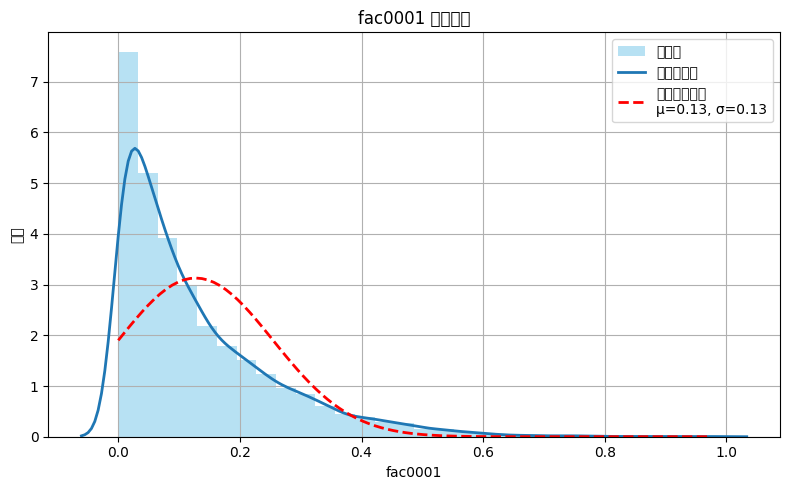

Log(数据) - D'Agostino and Pearson p值: 0.00000
❌ 取对数后仍不服从正态分布


/tmp/ipykernel_2005986/3109165204.py:83: UserWarning: Glyph 23494 (\N{CJK UNIFIED IDEOGRAPH-5BC6}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_2005986/3109165204.py:83: UserWarning: Glyph 24230 (\N{CJK UNIFIED IDEOGRAPH-5EA6}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_2005986/3109165204.py:83: UserWarning: Glyph 21462 (\N{CJK UNIFIED IDEOGRAPH-53D6}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_2005986/3109165204.py:83: UserWarning: Glyph 23545 (\N{CJK UNIFIED IDEOGRAPH-5BF9}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_2005986/3109165204.py:83: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_2005986/3109165204.py:83: UserWarning: Glyph 21518 (\N{CJK UNIFIED IDEOGRAPH-540E}) missing from current font.
  plt.tight_layout()
/tmp/ipykernel_2005986/3109165204.py:83: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from curren

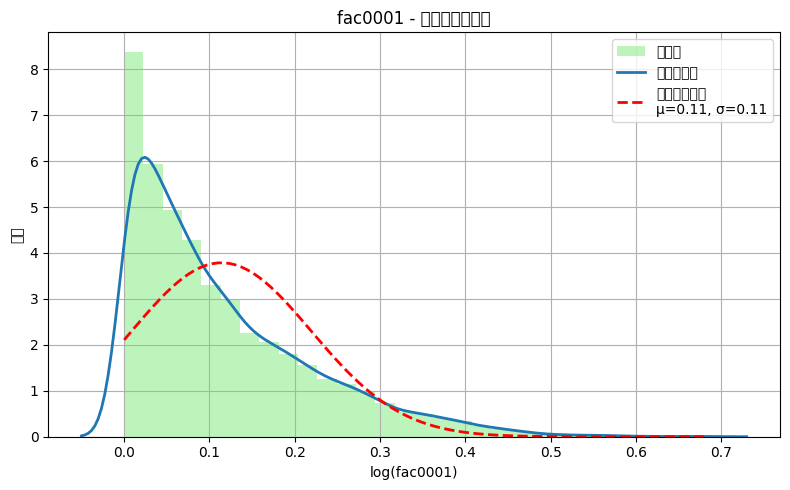

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


# 遍历数值型列
for col in data.select_dtypes(include='number').columns:
    if col in ['Code', 'date']:
        continue
    series = data[col].dropna()
    print(f'\n===> 检查列: {col}')

    # 超过10W样本时抽样
    if len(series) > 10000:
        series = pd.Series(np.random.choice(series.values, size=10000, replace=False))

    # 正态性检验
    if len(series) <= 5000:
        stat, p = stats.shapiro(series)
        print(f'Shapiro-Wilk p值: {p:.5f}')
    else:
        stat, p = stats.normaltest(series)
        print(f'D\'Agostino and Pearson p值: {p:.5f}')
    
    is_normal = p > 0.05
    print("✅ 可能服从正态分布" if is_normal else "❌ 不服从正态分布")

    # 可视化原始数据
    plt.figure(figsize=(8, 5))
    plt.hist(series, bins=30, density=True, alpha=0.6, color='skyblue', label='直方图')
    sns.kdeplot(series, linewidth=2, label='核密度估计')
    mu, std = stats.norm.fit(series)
    x = np.linspace(series.min(), series.max(), 100)
    p_norm = stats.norm.pdf(x, mu, std)
    plt.plot(x, p_norm, 'r--', linewidth=2, label=f'正态分布拟合\nμ={mu:.2f}, σ={std:.2f}')
    plt.xlabel(col)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # 若不服从正态分布，尝试 log 变换
    if not is_normal:
        # 检查是否有非正值，避免对数变换错误
        if (series <= 0).any():
            series = series + abs(series.min()) + 1  # 平移数据使其全为正值

        log_series = np.log(series)

        # 再次正态性检验
        if len(log_series) <= 5000:
            stat_log, p_log = stats.shapiro(log_series)
            print(f'Log(数据) - Shapiro-Wilk p值: {p_log:.5f}')
        else:
            stat_log, p_log = stats.normaltest(log_series)
            print(f'Log(数据) - D\'Agostino and Pearson p值: {p_log:.5f}')

        if p_log > 0.05:
            print("✅ 取对数后可能服从正态分布")
        else:
            print("❌ 取对数后仍不服从正态分布")

        # 绘制 log 后的分布
        plt.figure(figsize=(8, 5))
        plt.hist(log_series, bins=30, density=True, alpha=0.6, color='lightgreen', label='直方图')
        sns.kdeplot(log_series, linewidth=2, label='核密度估计')
        mu_log, std_log = stats.norm.fit(log_series)
        x_log = np.linspace(log_series.min(), log_series.max(), 100)
        p_log_norm = stats.norm.pdf(x_log, mu_log, std_log)
        plt.plot(x_log, p_log_norm, 'r--', linewidth=2, label=f'正态分布拟合\nμ={mu_log:.2f}, σ={std_log:.2f}')
        plt.xlabel(f'log({col})')
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    # 可选：只测试一个因子
    break
